## Correlación Canónica y Análisis Factorial

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_iris, load_breast_cancer, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.cross_decomposition import CCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score, roc_auc_score

import statsmodels.api as sm
from scipy import stats

%matplotlib inline
sns.set_style('whitegrid')

In [2]:
# ============================================================
# EJEMPLO 1: ANÁLISIS DE CORRELACIÓN CANÓNICA (CCA)
# ============================================================

# Dataset Wine: medimos dos conjuntos de variables
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine['Clase'] = wine.target

# Conjunto X: características minerales y fenoles. Conjunto Y: composición del vino
X_cca = df_wine[['alcalinity_of_ash', 'magnesium', 'total_phenols']].values
Y_cca = df_wine[['alcohol', 'malic_acid', 'ash']].values

print("Conjunto X (alcalinidad, magnesio y fenoles):", X_cca.shape)
print("Conjunto Y (alcohol, ácido málico y ceniza):", Y_cca.shape)
print("\nPrimeras filas:")
df_wine.head()

Conjunto X (alcalinidad, magnesio y fenoles): (178, 3)
Conjunto Y (alcohol, ácido málico y ceniza): (178, 3)

Primeras filas:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
# Estandarizar antes de CCA
scaler = StandardScaler()
X_cca_std = scaler.fit_transform(X_cca)
Y_cca_std = scaler.fit_transform(Y_cca)

# Ajustar CCA con 2 componentes
cca = CCA(n_components=2)
U, V = cca.fit_transform(X_cca_std, Y_cca_std)

# Correlaciones canónicas
rho = [np.corrcoef(U[:, i], V[:, i])[0, 1] for i in range(2)]
print("Correlaciones canónicas:")
for i, r in enumerate(rho):
    print(f"  ρ_{i+1} = {r:.4f}  (ρ² = {r**2:.4f})")

Correlaciones canónicas:
  ρ_1 = 0.6592  (ρ² = 0.4346)
  ρ_2 = 0.5216  (ρ² = 0.2720)


In [4]:
# Pesos canónicos (coeficientes)
vars_X = ['alcalinity_of_ash', 'magnesium', 'total_phenols']
vars_Y = ['alcohol', 'malic_acid', 'ash']
pesos_X = pd.DataFrame(cca.x_weights_, index=vars_X, columns=['U1', 'U2'])
pesos_Y = pd.DataFrame(cca.y_weights_, index=vars_Y, columns=['V1', 'V2'])

print("Pesos canónicos para X:")
print(pesos_X.round(4))
print("\nPesos canónicos para Y:")
print(pesos_Y.round(4))

# Cargas canónicas (correlación entre variable original y variable canónica)
cargas_X = pd.DataFrame(
    [np.corrcoef(X_cca_std[:, j], U[:, i])[0, 1]
     for i in range(2) for j in range(len(vars_X))],
    index=[f'U{i+1}-{nombre}' for i in range(2) for nombre in vars_X],
    columns=['Carga']
)
print("\nCargas canónicas para X:")
print(cargas_X.round(4))

Pesos canónicos para X:
                       U1      U2
alcalinity_of_ash  0.9880 -0.0834
magnesium          0.1544  0.5278
total_phenols      0.0011  0.8453

Pesos canónicos para Y:
                V1      V2
alcohol    -0.5683  0.5025
malic_acid  0.3243 -0.5910
ash         0.7562  0.6310

Cargas canónicas para X:
                       Carga
U1-alcalinity_of_ash  0.9877
U1-magnesium          0.0732
U1-total_phenols     -0.2869
U2-alcalinity_of_ash -0.1077
U2-magnesium          0.6836
U2-total_phenols      0.8378


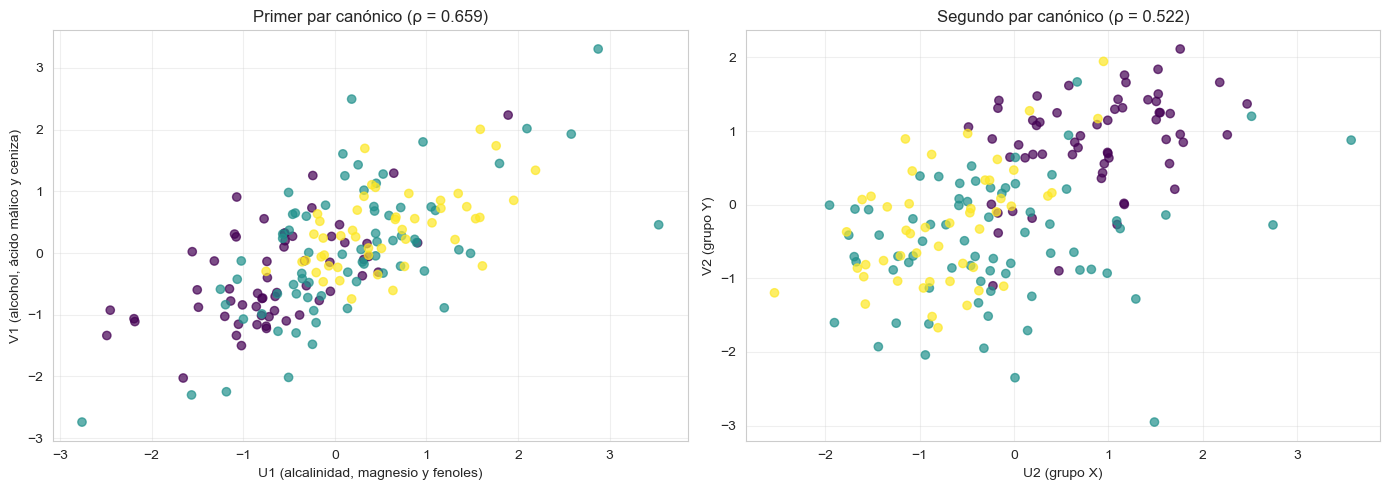

In [5]:
# Scatter de las variables canónicas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par canónico 1
axes[0].scatter(U[:, 0], V[:, 0], c=wine.target, cmap='viridis', alpha=0.7)
axes[0].set_xlabel('U1 (alcalinidad, magnesio y fenoles)')
axes[0].set_ylabel('V1 (alcohol, ácido málico y ceniza)')
axes[0].set_title(f'Primer par canónico (ρ = {rho[0]:.3f})')
axes[0].grid(True, alpha=0.3)

# Par canónico 2
axes[1].scatter(U[:, 1], V[:, 1], c=wine.target, cmap='viridis', alpha=0.7)
axes[1].set_xlabel('U2 (grupo X)')
axes[1].set_ylabel('V2 (grupo Y)')
axes[1].set_title(f'Segundo par canónico (ρ = {rho[1]:.3f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# PARTE 2: ANÁLISIS FACTORIAL (AF)
# ============================================================

# Dataset Wine: 13 variables químicas del vino
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = wine.target

print(f"Forma del dataset: {X_wine.shape}")
print(f"Variables: {X_wine.shape[1]}")
print(f"\nPrimeras variables:")
print(list(X_wine.columns[:10]))

Forma del dataset: (178, 13)
Variables: 13

Primeras variables:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity']


In [7]:
# Seleccionar 8 variables representativas para análisis factorial
vars_fa = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash',
           'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols']

X_fa = X_wine[vars_fa].values
X_fa_std = StandardScaler().fit_transform(X_fa)

print(f"Variables seleccionadas: {len(vars_fa)}")
print(f"Forma: {X_fa_std.shape}")

Variables seleccionadas: 8
Forma: (178, 8)


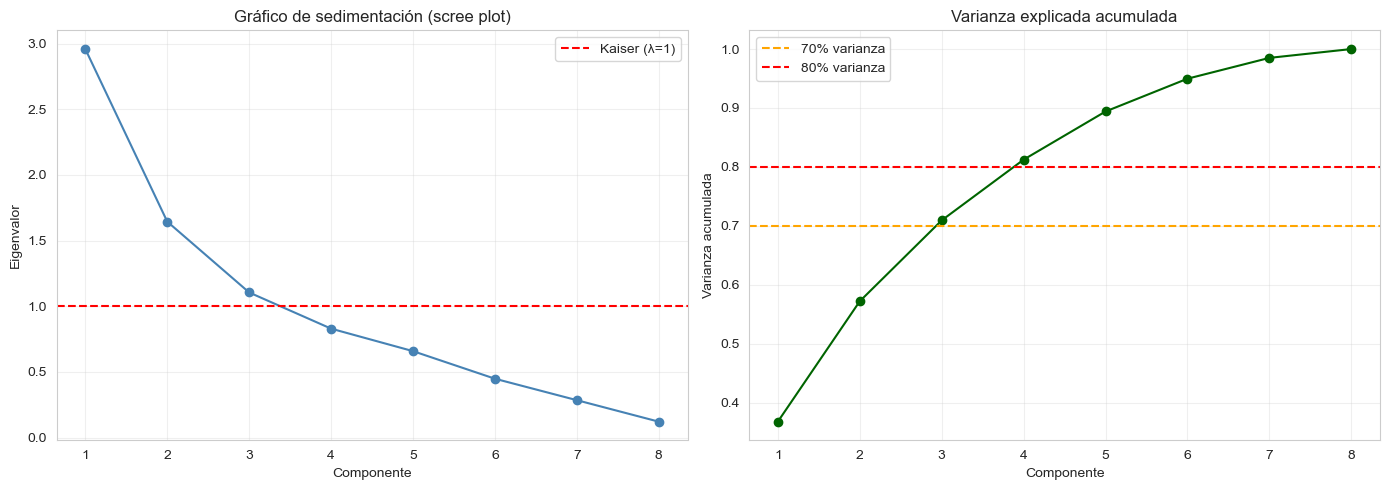


Factores con eigenvalor > 1: 3
Varianza acumulada con 3 factores: 0.709


In [8]:
# Gráfico de sedimentación (scree plot)
pca_temp = PCA()
pca_temp.fit(X_fa_std)
eigenvalues = pca_temp.explained_variance_
varianza_acum = np.cumsum(pca_temp.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Gráfico de sedimentación (scree plot)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(varianza_acum) + 1), varianza_acum, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70% varianza')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% varianza')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Regla de Kaiser
n_factores = max(1, sum(eigenvalues > 1))
print(f"\nFactores con eigenvalor > 1: {n_factores}")
print(f"Varianza acumulada con {n_factores} factores: {varianza_acum[n_factores-1]:.3f}")

In [9]:
# Extraer factores con FactorAnalysis (máxima verosimilitud)
fa = FactorAnalysis(n_components=n_factores, random_state=42)
scores_fa = fa.fit_transform(X_fa_std)

# Cargas factoriales
cargas_fa = pd.DataFrame(fa.components_.T,
                          index=vars_fa,
                          columns=[f'F{i+1}' for i in range(n_factores)])

print("Cargas factoriales:")
print(cargas_fa.round(3))

Cargas factoriales:
                         F1     F2     F3
alcohol               0.281 -0.216 -0.765
malic_acid           -0.410 -0.258 -0.160
ash                   0.125 -0.911  0.025
alcalinity_of_ash    -0.373 -0.527  0.414
magnesium             0.223 -0.259 -0.230
total_phenols         0.882 -0.028 -0.040
flavanoids            0.981  0.010  0.048
nonflavanoid_phenols -0.547 -0.265  0.088


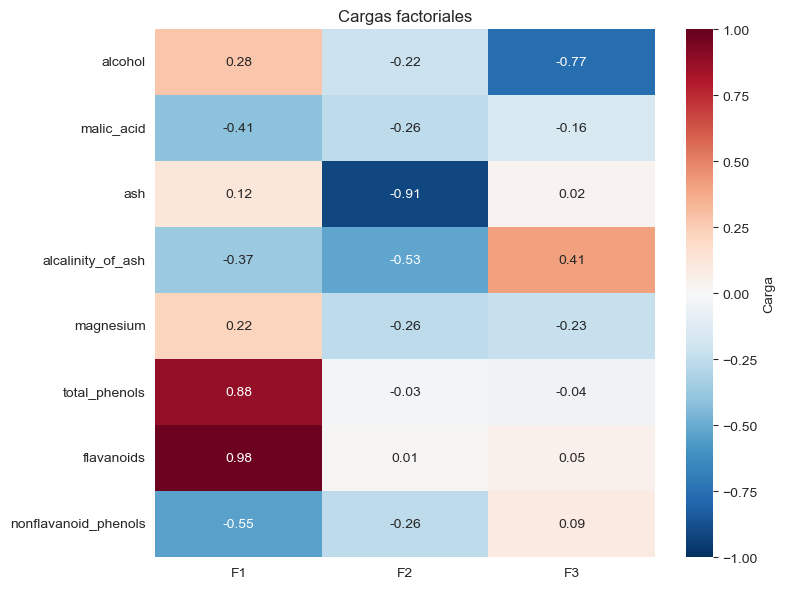


Comunalidades (varianza explicada por factores):
alcohol                 0.711
malic_acid              0.260
ash                     0.845
alcalinity_of_ash       0.588
magnesium               0.169
total_phenols           0.781
flavanoids              0.964
nonflavanoid_phenols    0.377
dtype: float64


In [10]:
# Heatmap de cargas factoriales
plt.figure(figsize=(8, 6))
sns.heatmap(cargas_fa, annot=True, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales')
plt.tight_layout()
plt.show()

# Comunalidades (proporción de varianza explicada por los factores)
comunalidades = (cargas_fa ** 2).sum(axis=1)
print("\nComunalidades (varianza explicada por factores):")
print(comunalidades.round(3))

In [11]:
# ============================================================
# EJEMPLO 3: ANÁLISIS FACTORIAL APLICADO A REGRESIÓN
# ============================================================

# Usamos los scores factoriales como predictores
# Objetivo: clasificar si el vino es de clase 0 o de las demás clases
# Clase 0 = 1, resto = 0
y_bin = (y_wine == 0).astype(int)

# Modelo 1: regresión con variables originales
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_fa_std, y_bin, test_size=0.3, random_state=42, stratify=y_bin
)

modelo_orig = LogisticRegression(max_iter=1000, random_state=42)
modelo_orig.fit(X_train_orig, y_train)
acc_orig = accuracy_score(y_test, modelo_orig.predict(X_test_orig))

# Modelo 2: regresión con scores factoriales
X_train_fa, X_test_fa, _, _ = train_test_split(
    scores_fa, y_bin, test_size=0.3, random_state=42, stratify=y_bin
)

modelo_fa = LogisticRegression(max_iter=1000, random_state=42)
modelo_fa.fit(X_train_fa, y_train)
acc_fa = accuracy_score(y_test, modelo_fa.predict(X_test_fa))

print("=== COMPARACIÓN DE MODELOS ===\n")
print(f"Modelo con variables originales ({X_fa.shape[1]} vars):")
print(f"  Accuracy: {acc_orig:.4f}")
print(f"\nModelo con factores ({n_factores} factores):")
print(f"  Accuracy: {acc_fa:.4f}")
print(f"\nReducción de dimensionalidad: {X_fa.shape[1]} → {n_factores}")

=== COMPARACIÓN DE MODELOS ===

Modelo con variables originales (8 vars):
  Accuracy: 0.9444

Modelo con factores (3 factores):
  Accuracy: 0.9074

Reducción de dimensionalidad: 8 → 3
